# DATA 202 Final Project: Does Payroll Buy Wins?
## Notebook 01: Scrape 2026 Payrolls from Spotrac

**Students:** Asher Ring & Elliot Asquith

**What this notebook does:** Collects every 2026 MLB contract line from [Spotrac](https://www.spotrac.com/mlb/) (MLB itself does not publish payroll data), builds one payroll row per team, checks that every team's payroll parts add up to Spotrac's total, and saves the results.

**Reads:** Spotrac's league payroll page and all 30 team cap pages (internet connection needed; takes about 3 minutes because of the 5-second crawl delay)

**Creates:** `data/mlb_team_payroll_totals.csv` (30 teams), `data/mlb_player_salaries.csv` (2,043 contract lines), `data/data_issues_log.csv` (oddities in Spotrac's own data), `images/team_payrolls.png`

**Slides it supports:** What Each Dataset's Columns Hold, and every payroll number in the presentation

### About the data

1. **Team table** (`mlb_team_payroll_totals.csv`): one row per team with its record, average age, and total payroll split into active, injured, suspended, personal leave, minor league, dead money and retained money. The parts add up to `total_payroll` exactly.
2. **Player table** (`mlb_player_salaries.csv`): one row per contract line from **every** table on each team's cap page: active roster, injured list, suspended/restricted, personal leave, minor league, dead money and retained.

**Two salary columns, on purpose:**
- `payroll_salary` = the player's full-season salary (what you'd quote for "what does he make?").
- `payroll_salary_adjusted` = the share this team actually carries (prorated for days on the roster, trades, call-ups). **Use this one for team-cost analysis**; these add up to Spotrac's team totals.

**Scraping etiquette:**
- Spotrac's `robots.txt` allows these pages but sets `Crawl-delay: 5`, so we wait 5 seconds between requests.
- Spotrac blocks the default `requests` user agent, so we send a normal browser User-Agent header.
- Spotrac sometimes serves a reduced page (no roster tables, or a simplified league table), so requests are retried until the full page comes back.
- Rerunning pulls the live pages. The 2026 season is over, so the numbers should stay the same unless Spotrac revises them.

In [5]:
import re
import time
import requests
from bs4 import BeautifulSoup
import pandas as pd
from pathlib import Path

DATA_DIR = Path("data")
IMG_DIR = Path("images")
DATA_DIR.mkdir(exist_ok=True)
IMG_DIR.mkdir(exist_ok=True)

YEAR = 2026
PAYROLL_URL = f"https://www.spotrac.com/mlb/payroll/_/year/{YEAR}"
HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
        "(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
    )
}
CRAWL_DELAY_SECONDS = 5  # matches Spotrac's robots.txt Crawl-delay for generic bots


def money_to_int(text):
    """'$378,348,911' -> 378348911, '-$38,127' or '($38,127)' -> -38127, '-' or '' -> None."""
    if text is None:
        return None
    cleaned = text.strip().replace("$", "").replace(",", "")
    if cleaned in ("", "-"):
        return None
    negative = cleaned.startswith("-") or cleaned.startswith("(")
    try:
        value = int(cleaned.strip("()-"))
    except ValueError:
        return None
    return -value if negative else value


def clean_text(text):
    """Collapse internal whitespace/newlines, e.g. 'SP\n\t\t/DH' -> 'SP/DH'."""
    return " ".join(text.split()).replace(" /", "/").replace("/ ", "/")


def get_html(url, must_contain, tries=4):
    """GET a page, retrying (with the crawl delay) until it contains `must_contain`.

    Spotrac occasionally serves a bot-check or reduced page; that used to make a
    team silently fail or come back with the wrong table layout.
    """
    for attempt in range(1, tries + 1):
        r = requests.get(url, headers=HEADERS, timeout=30, allow_redirects=True)
        r.raise_for_status()
        if re.search(must_contain, r.text):
            return r.text
        print(f"  (reduced page on attempt {attempt}, retrying)")
        time.sleep(CRAWL_DELAY_SECONDS * 2)
    raise RuntimeError(f"never got the full page for {url}")

In [6]:
%pip install lxml
%pip install curl_cffi

from curl_cffi import requests as cffi_requests

def get_html(url, must_contain, tries=4):
    for attempt in range(1, tries + 1):
        r = cffi_requests.get(url, impersonate="chrome", timeout=30)
        if r.status_code == 403:
            print(f"  (403 on attempt {attempt}, retrying)")
            time.sleep(CRAWL_DELAY_SECONDS * 2)
            continue
        r.raise_for_status()
        if re.search(must_contain, r.text):
            return r.text
        print(f"  (reduced page on attempt {attempt}, retrying)")
        time.sleep(CRAWL_DELAY_SECONDS * 2)
    raise RuntimeError(f"never got the full page for {url}")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Step 1: League payroll table — team list, record, average age

One request. We only take the team links, record and average age from here; the dollar breakdown comes from each team's own page in Step 2, which is more detailed.

> Note: this table's columns are labelled "Retained" and "Buried", but they hold Spotrac's **dead money** and **minor-league** amounts. It has no column for money retained in trades, so its parts don't add up to its total. That's why we don't use its breakdown.

In [7]:
html = get_html(PAYROLL_URL, must_contain=r'class="[^"]*dataTable[^"]*premium')
table = BeautifulSoup(html, "lxml").select_one("table.dataTable.premium")

league_rows = []
for row in table.tbody.find_all("tr"):
    cells = row.find_all("td")
    if len(cells) < 9:
        continue
    team_link_tag, team_abbr_tag = cells[1].find("a"), cells[1].find("span")
    if team_link_tag is None or team_abbr_tag is None:
        continue  # skips the "Averages" summary row
    league_rows.append({
        "team": team_abbr_tag.get_text(strip=True),
        "record": cells[2].get_text(strip=True),
        "avg_age": float(cells[3].get_text(strip=True)) if cells[3].get_text(strip=True) else None,
        "league_table_total": money_to_int(cells[4].get_text(strip=True)),
        "team_cap_page_url": team_link_tag["href"],
    })

league_df = pd.DataFrame(league_rows)
assert len(league_df) == 30, f"expected 30 teams, got {len(league_df)}"
print(f"Fetched {len(league_df)} teams")
league_df.head()

Fetched 30 teams


,team,record,avg_age,league_table_total,team_cap_page_url
0,NYM,74-88,28.0,345165305,https://www.spotrac.com/redirect/team/48/cap/2026
1,LAD,100-62,30.4,339319244,https://www.spotrac.com/redirect/team/59/cap/2026
2,NYY,93-68,30.0,306689555,https://www.spotrac.com/redirect/team/34/cap/2026
3,PHI,88-74,30.0,291951676,https://www.spotrac.com/redirect/team/49/cap/2026
4,TOR,79-83,28.1,275309179,https://www.spotrac.com/redirect/team/36/cap/2026


## Step 2: Every contract line, team by team

Each team's cap page has one table per roster group, each under its own heading (active roster, injured list, dead money, retained, minor league, and for some teams suspended/restricted or personal leave), plus a **Payroll Totals** summary box. We read all of them.

This makes 30 requests with a 5-second delay — expect this cell to take **~3 minutes**.

In [8]:
GROUP_BY_HEADING = {
    f"{YEAR} Active Roster Payroll": "active",
    f"{YEAR} Injured List Payroll": "injured",
    f"{YEAR} Suspended/Restricted Payroll": "suspended",
    f"{YEAR} Personal Leave Payroll": "personal_leave",
    f"{YEAR} Minor": "minor",
    f"{YEAR} Dead Money Payroll": "dead",
    f"{YEAR} Retained Payroll": "retained",
}
SUMMARY_LABELS = {
    "Active Roster": "active", "Injured List": "injured", "Suspended/Restricted": "suspended",
    "Personal Leave": "personal_leave", "Minor": "minor", "Dead Money": "dead", "Retained": "retained",
    "Deferred": "deferred", "Signing Bonus": "signing_bonus",
    "Total Adjusted Payroll Allocations": "total",
}


def table_heading(tbl):
    heading = tbl.find_previous(["h2", "h3", "h4", "header"])
    return clean_text(heading.get_text()) if heading else ""


def parse_team_page(team_abbr, html):
    """Return (player rows, payroll-summary dict) for one team's cap page."""
    page = BeautifulSoup(html, "lxml")
    rows, summary = [], {"team": team_abbr}
    for tbl in page.find_all("table"):
        heading = table_heading(tbl)
        if heading == f"{YEAR} Payroll Totals":
            for tr in tbl.find_all("tr"):
                cells = [clean_text(c.get_text()) for c in tr.find_all(["td", "th"])]
                if len(cells) >= 2 and cells[0] in SUMMARY_LABELS:
                    summary[SUMMARY_LABELS[cells[0]]] = money_to_int(cells[1])
            continue
        first_header = tbl.select_one("thead th")
        if first_header is None or not clean_text(first_header.get_text()).startswith("Player"):
            continue
        group = GROUP_BY_HEADING.get(heading)
        if group is None:
            # A table type we haven't seen before -- stop rather than silently skip money.
            raise RuntimeError(f"{team_abbr}: unknown player table '{heading}'")
        expected = int(re.search(r"\((\d+)\)", first_header.get_text()).group(1))
        parsed = 0
        for tr in tbl.tbody.find_all("tr") if tbl.tbody else []:
            cells = tr.find_all("td")
            if len(cells) < 7:
                continue
            # The name cell also holds a hidden last-name <span> and an IL/TRADED note,
            # so read the player link and the note separately.
            link = cells[0].find("a", class_="link")
            note = cells[0].find("div", class_="text-muted")
            rows.append({
                "team": team_abbr,
                "roster_group": group,
                "player": clean_text(link.get_text()) if link else clean_text(cells[0].get_text()),
                "position": clean_text(cells[1].get_text()),
                "note": clean_text(note.get_text()) if note else "",
                "contract_status": clean_text(cells[4].get_text()) or None,
                "payroll_salary": money_to_int(cells[5].get_text()),
                "payroll_salary_adjusted": money_to_int(cells[6].get_text()),
                "base_salary": money_to_int(cells[7].get_text()) if len(cells) > 7 else None,
                "signing_bonus": money_to_int(cells[8].get_text()) if len(cells) > 8 else None,
                "player_url": link.get("href") if link else None,
            })
            parsed += 1
        if parsed != expected:
            raise RuntimeError(f"{team_abbr} {group}: header says {expected} players, parsed {parsed}")
    if "total" not in summary:
        raise RuntimeError(f"{team_abbr}: no Payroll Totals box found")
    return rows, summary


all_players, summaries = [], []
for i, team in enumerate(league_df.itertuples(), start=1):
    time.sleep(CRAWL_DELAY_SECONDS)
    print(f"[{i}/{len(league_df)}] {team.team} ...", end=" ")
    html = get_html(team.team_cap_page_url, must_contain=r'id="table_active"')
    rows, summary = parse_team_page(team.team, html)
    all_players.extend(rows)
    summaries.append(summary)
    print(f"{len(rows)} rows")

players_df = pd.DataFrame(all_players)
players_df.insert(3, "player_id", players_df["player_url"].str.extract(r"/id/(\d+)/", expand=False).astype("Int64"))
for col in ["payroll_salary", "payroll_salary_adjusted", "base_salary", "signing_bonus"]:
    players_df[col] = players_df[col].astype("Int64")
summary_df = pd.DataFrame(summaries).fillna(0)

print(f"\nTotal rows across the league: {len(players_df)}")
print(players_df["roster_group"].value_counts().to_string())
players_df.head()

[1/30] NYM ... 80 rows
[2/30] LAD ... 63 rows
[3/30] NYY ... 52 rows
[4/30] PHI ... 64 rows
[5/30] TOR ... 75 rows
[6/30] ATL ... 84 rows
[7/30] CHC ... 76 rows
[8/30] HOU ... 63 rows
[9/30] SD ... 65 rows
[10/30] BOS ... 66 rows
[11/30] DET ... 70 rows
[12/30] ARI ... 62 rows
[13/30] TEX ... 64 rows
[14/30] SF ... 83 rows
[15/30] LAA ... 69 rows
[16/30] SEA ... 71 rows
[17/30] BAL ... 80 rows
[18/30] KC ... 63 rows
[19/30] MIL ... 71 rows
[20/30] CIN ... 62 rows
[21/30] COL ... 66 rows
[22/30] MIN ... 67 rows
[23/30] PIT ... 61 rows
[24/30] CHW ... 69 rows
[25/30] WSH ... 73 rows
[26/30] ATH ... 72 rows
[27/30] TB ... 67 rows
[28/30] STL ... 56 rows
[29/30] MIA ... 60 rows
[30/30] CLE ... 57 rows

Total rows across the league: 2031
roster_group
active            834
dead              502
minor             398
injured           267
retained           21
suspended           6
personal_leave      3


,team,roster_group,player,player_id,position,note,contract_status,payroll_salary,payroll_salary_adjusted,base_salary,signing_bonus,player_url
0,NYM,active,Juan Soto,25959,LF,,Veteran,61975000,61975000,46875000,15000000,https://www.spotrac.com/mlb/player/_/id/25959/...
1,NYM,active,Bo Bichette,19942,3B,,Veteran,42000000,42000000,2000000,40000000,https://www.spotrac.com/mlb/player/_/id/19942/...
2,NYM,active,Francisco Lindor,14113,SS,,Veteran,34100000,32477821,32000000,2100000,https://www.spotrac.com/mlb/player/_/id/14113/...
3,NYM,active,Marcus Semien,14066,2B,,Veteran,26000000,26000000,26000000,<NA>,https://www.spotrac.com/mlb/player/_/id/14066/...
4,NYM,active,Sean Manaea,19022,SP,,Veteran,25000000,19680726,25000000,<NA>,https://www.spotrac.com/mlb/player/_/id/19022/...


## Step 3: Team payroll totals

Each category is the sum of that group's `payroll_salary_adjusted`. The one exception is the minor-league line, which we take from Spotrac's summary box: for a few teams Spotrac's minor-league table lists slightly more than its own summary counts. With that, the categories add up to Spotrac's `total_payroll` exactly for every team (checked below).

In [9]:
by_group = (
    players_df.pivot_table(index="team", columns="roster_group", values="payroll_salary_adjusted", aggfunc="sum")
    .reindex(columns=list(GROUP_BY_HEADING.values()))
    .fillna(0).astype("int64")
)
team_totals_df = league_df.merge(summary_df[["team", "minor", "deferred", "signing_bonus", "total"]], on="team")
team_totals_df = team_totals_df.merge(by_group.drop(columns="minor").reset_index(), on="team")
team_totals_df = team_totals_df.rename(columns={
    "total": "total_payroll", "active": "active_payroll", "injured": "injured_payroll",
    "suspended": "suspended_payroll", "personal_leave": "personal_leave_payroll",
    "minor": "minor_league_payroll", "dead": "dead_money", "retained": "retained_payroll",
    "deferred": "deferred_payroll", "signing_bonus": "signing_bonus_payroll",
})
# Spotrac only gives team codes, so add the full names (used for labels and joins)
TEAM_NAMES = {
    "ARI": "Arizona Diamondbacks", "ATH": "Athletics", "ATL": "Atlanta Braves", "BAL": "Baltimore Orioles",
    "BOS": "Boston Red Sox", "CHC": "Chicago Cubs", "CHW": "Chicago White Sox", "CIN": "Cincinnati Reds",
    "CLE": "Cleveland Guardians", "COL": "Colorado Rockies", "DET": "Detroit Tigers", "HOU": "Houston Astros",
    "KC": "Kansas City Royals", "LAA": "Los Angeles Angels", "LAD": "Los Angeles Dodgers", "MIA": "Miami Marlins",
    "MIL": "Milwaukee Brewers", "MIN": "Minnesota Twins", "NYM": "New York Mets", "NYY": "New York Yankees",
    "PHI": "Philadelphia Phillies", "PIT": "Pittsburgh Pirates", "SD": "San Diego Padres", "SF": "San Francisco Giants",
    "SEA": "Seattle Mariners", "STL": "St. Louis Cardinals", "TB": "Tampa Bay Rays", "TEX": "Texas Rangers",
    "TOR": "Toronto Blue Jays", "WSH": "Washington Nationals",
}
team_totals_df["team_name"] = team_totals_df["team"].map(TEAM_NAMES)
assert team_totals_df["team_name"].notna().all()

team_totals_df[["wins", "losses"]] = team_totals_df["record"].str.split("-", expand=True).astype(int)
team_totals_df["win_pct"] = (team_totals_df["wins"] / (team_totals_df["wins"] + team_totals_df["losses"])).round(3)

PARTS = ["active_payroll", "injured_payroll", "suspended_payroll", "personal_leave_payroll",
         "minor_league_payroll", "dead_money", "retained_payroll", "deferred_payroll", "signing_bonus_payroll"]
PARTS = [c for c in PARTS if team_totals_df[c].ne(0).any()]  # drop categories that are $0 for every team
team_totals_df = team_totals_df.sort_values("total_payroll", ascending=False).reset_index(drop=True)
team_totals_df.insert(0, "rank", range(1, len(team_totals_df) + 1))
team_totals_df = team_totals_df[["rank", "team", "team_name", "record", "wins", "losses", "win_pct", "avg_age", "total_payroll"]
                                + PARTS + ["league_table_total", "team_cap_page_url"]]
team_totals_df.head()

,rank,team,team_name,record,wins,losses,win_pct,avg_age,total_payroll,active_payroll,injured_payroll,suspended_payroll,personal_leave_payroll,minor_league_payroll,dead_money,retained_payroll,league_table_total,team_cap_page_url
0,1,NYM,New York Mets,74-88,74,88,0.457,28.0,345165305,223810168,23291093,0,0,3272458,66041586,28750000,345165305,https://www.spotrac.com/redirect/team/48/cap/2026
1,2,LAD,Los Angeles Dodgers,100-62,100,62,0.617,30.4,339319244,304389785,21040000,0,0,9823331,4066128,0,339319244,https://www.spotrac.com/redirect/team/59/cap/2026
2,3,NYY,New York Yankees,93-68,93,68,0.578,30.0,306689555,223814991,47640078,0,0,4966471,30268015,0,306689555,https://www.spotrac.com/redirect/team/34/cap/2026
3,4,PHI,Philadelphia Phillies,88-74,88,74,0.543,30.0,291951676,225762422,19826786,0,0,4399092,41963376,0,291951676,https://www.spotrac.com/redirect/team/49/cap/2026
4,5,TOR,Toronto Blue Jays,79-83,79,83,0.488,28.1,275309179,130236396,87264683,0,0,10432963,47375137,0,275309179,https://www.spotrac.com/redirect/team/36/cap/2026


## Step 4: Checks — stop here if anything fails

In [10]:
# 1. Every team's categories add up to its total.
gap = team_totals_df[PARTS].sum(axis=1) - team_totals_df["total_payroll"]
assert (gap == 0).all(), team_totals_df.loc[gap != 0, ["team"]].assign(gap=gap)

# 2. The league table and each team page agree on the total.
assert (team_totals_df["league_table_total"] == team_totals_df["total_payroll"]).all()

# 3. Active and injured player rows match Spotrac's summary box to the dollar.
s = summary_df.set_index("team")
for grp in ["active", "injured"]:
    diff = by_group[grp] - s[grp]
    assert (diff == 0).all(), diff[diff != 0]

# 4. Player rows vs team total (expected: off only by the minor-league quirk above).
row_total = players_df.groupby("team")["payroll_salary_adjusted"].sum() + s["deferred"] + s["signing_bonus"]
off = (row_total - s["total"])
print("Teams whose player rows don't sum to the total (minor-league quirk):")
print(off[off != 0].map("${:,.0f}".format).to_string() if (off != 0).any() else "  none")

# 5. Things to know about, not errors.
print("\nBlank adjusted salaries (Spotrac shows no amount):", players_df["payroll_salary_adjusted"].isna().sum())
print("Negative amounts (credits back to the team):", (players_df["payroll_salary_adjusted"] < 0).sum())
print("All checks passed.")

Teams whose player rows don't sum to the total (minor-league quirk):
team
ATH    $127,100
BAL     $63,600
DET    $140,022
NYM    $800,000
PIT    $850,000
SD     $780,000

Blank adjusted salaries (Spotrac shows no amount): 26
Negative amounts (credits back to the team): 5
All checks passed.


## Step 5: Save results to CSV

In [11]:
# Sort players by team (highest payroll first), then roster group, then salary
group_order = {group: i for i, group in enumerate(GROUP_BY_HEADING.values())}
team_order = dict(zip(team_totals_df["team"], team_totals_df["rank"]))
players_df = (players_df
              .assign(_team=players_df["team"].map(team_order), _group=players_df["roster_group"].map(group_order))
              .sort_values(["_team", "_group", "payroll_salary_adjusted"], ascending=[True, True, False], na_position="last")
              .drop(columns=["_team", "_group"])
              .reset_index(drop=True))

team_totals_df.drop(columns=["league_table_total"]).to_csv(DATA_DIR / "mlb_team_payroll_totals.csv", index=False)
players_df.to_csv(DATA_DIR / "mlb_player_salaries.csv", index=False)
print("Saved", DATA_DIR / "mlb_team_payroll_totals.csv", "and", DATA_DIR / "mlb_player_salaries.csv")

Saved data/mlb_team_payroll_totals.csv and data/mlb_player_salaries.csv


## Step 6: Log the oddities in Spotrac's own data

These are not scraping errors. They are how Spotrac publishes the numbers, so we keep them but write them down for the limitations slide.

In [12]:
issues = []

# Teams whose minor-league table lists more than Spotrac's own summary line
for team in team_totals_df["team"]:          # highest payroll first
    if off[team] != 0:
        issues.append({"team": team, "player": "", "issue": "team rows vs Spotrac total",
                       "detail": f"Minor-league table on Spotrac sums ${int(off[team]):,} more than its own 'Minor' summary line",
                       "action": "kept as published"})

# Lines where Spotrac shows no amount
for _, row in players_df[players_df["payroll_salary_adjusted"].isna()].iterrows():
    issues.append({"team": row["team"], "player": row["player"], "issue": "blank adjusted salary",
                   "detail": f"{row['roster_group']}; note '{row['note']}'; Spotrac shows no amount",
                   "action": "left blank (not zero)"})

# Negative amounts are credits back to a team
for _, row in players_df[players_df["payroll_salary_adjusted"] < 0].iterrows():
    issues.append({"team": row["team"], "player": row["player"], "issue": "negative amount",
                   "detail": f"{row['roster_group']} ${row['payroll_salary_adjusted']:,} ({row['note']}) — a credit back to the team",
                   "action": "kept as published"})

# The same player and amount listed twice
repeats = players_df[players_df.duplicated(subset=["team", "roster_group", "player", "payroll_salary_adjusted"])]
for _, row in repeats.iterrows():
    issues.append({"team": row["team"], "player": row["player"], "issue": "possible duplicate line",
                   "detail": f"two {row['roster_group']} lines of ${row['payroll_salary_adjusted']:,}",
                   "action": "kept (Spotrac lists both; check before summing)"})

# Ohtani's contract is mostly deferred
for _, row in players_df[players_df["player"].str.contains("Ohtani")].iterrows():
    issues.append({"team": row["team"], "player": row["player"], "issue": "deferred contract",
                   "detail": "listed at $70M payroll salary; most of it is paid later as deferred money",
                   "action": "kept as published"})

issues_df = pd.DataFrame(issues)
issues_df.to_csv(DATA_DIR / "data_issues_log.csv", index=False)
print(issues_df["issue"].value_counts().to_string())

issue
blank adjusted salary         26
team rows vs Spotrac total     6
negative amount                5
possible duplicate line        2
deferred contract              1


## Step 7: Quick look — team payrolls, highest to lowest

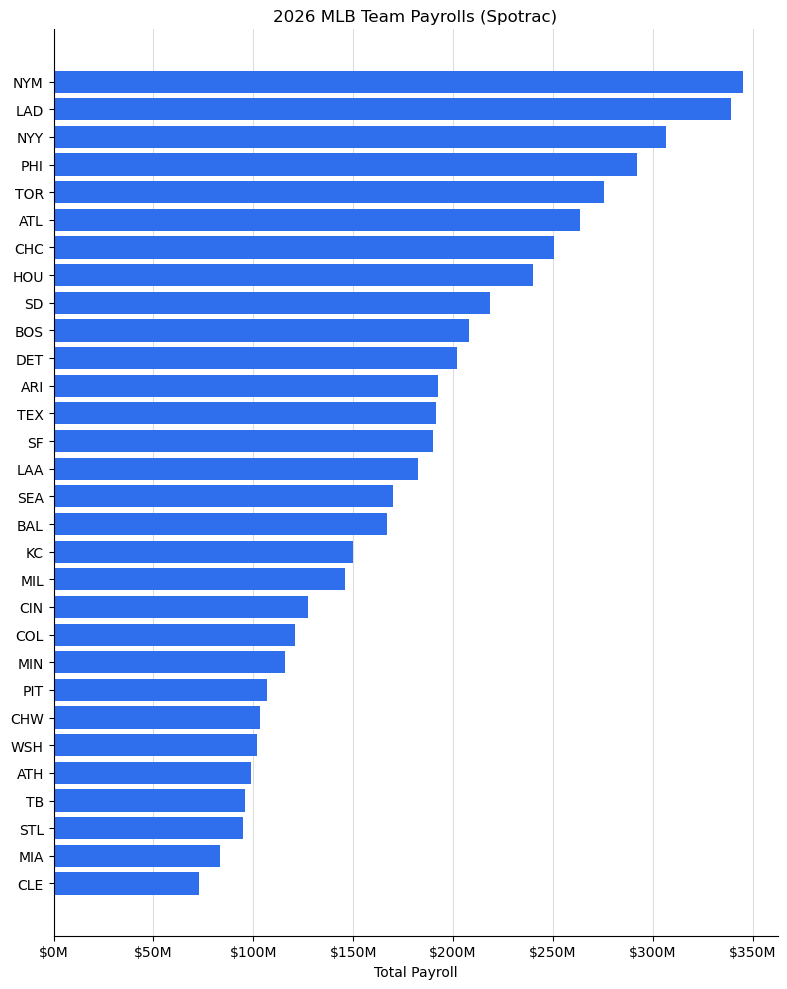

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plot_df = team_totals_df.sort_values("total_payroll", ascending=True)

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(plot_df["team"], plot_df["total_payroll"], color="#2f6fed")

ax.set_xlabel("Total Payroll")
ax.set_title(f"{YEAR} MLB Team Payrolls (Spotrac)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1e6:,.0f}M"))
ax.grid(axis="x", color="#dddddd", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(IMG_DIR / "team_payrolls.png", dpi=200)
plt.show()